In [1]:
import sys
sys.path.append("../source")

import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import diffrax as dfx

from core.spacing import LinearSpacing, SpacingExtent, NUM_GHOSTS
from core.grid import Grid
from core.statevector import StateVector
from core.rhsevolution import get_rhs
from matter.scalarmatter import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.bssnstatevariables import idx_phi, idx_lapse
from bssn.constraintsdiagnostic import get_constraints_diagnostic

In [2]:
A = 0.22 # amplitude
r0 = 0
sigma = 1.0

num_points = 401
r_max = 10.0

T = 6.0 # initial maximum time evolution
T_MAX = 24.0 # stop extending unresolved runs at this time
T_EXTENSION_FACTOR = 1.25 # multiply the run time when extending
SUBCRITICAL_FINAL_LAPSE = 0.9 # classify as subcritical if the final lapse is above this

# Provisional subcritical test: require a clear rise from the lapse minimum,
# and reject a substantial drop in the final half time unit.
RECOVERY_WINDOW_TIME = 0.5
RECOVERY_MIN_RISE = 0.05
RECOVERY_MAX_LATE_DROP = 0.03
num_output_times = 101 # number of times to save the output
dt0 = 0.005 

matter = ScalarMatter(a_scalar_mu=0.0)
state_vector = StateVector(matter)

spacing = LinearSpacing(
    num_points=num_points,
    r_max=r_max,
    extent=SpacingExtent.HALF,
)
grid = Grid(spacing, state_vector)
background = FlatSphericalBackground(grid.r)

physical = slice(NUM_GHOSTS, -NUM_GHOSTS)
r_physical = grid.r[physical]
dr = grid.derivs.dx

In [3]:
def scalar_profile(r, amplitude, sigma):
    return amplitude * r**2 * jnp.exp(-(r / sigma)**2)

scalar_profile_dr = jax.grad(scalar_profile, argnums=0)




In [4]:
def solve_psi(r_aux, dr, amplitude, r0, sigma):
    du_dr = jax.vmap(
    scalar_profile_dr,
    in_axes=(0, None, None),)(r_aux, amplitude, sigma)

    source = jnp.pi * du_dr**2
    n = r_aux.size

    main_diag = source * dr**2 - 2.0
    main_diag = main_diag.at[0].add(1.0 - dr / r_aux[0])

    outer_factor = (
        2.0 * dr / r_aux[-1]
        * (1.0 + dr / r_aux[-1])
    )
    main_diag = main_diag.at[-1].add(-outer_factor)

    lower_diag = jnp.zeros_like(r_aux)
    upper_diag = jnp.zeros_like(r_aux)

    upper_diag = upper_diag.at[:-1].set(
        1.0 + dr / r_aux[:-1]
    )
    lower_diag = lower_diag.at[1:].set(
        1.0 - dr / r_aux[1:]
    )
    lower_diag = lower_diag.at[-1].set(2.0)

    rhs = jnp.zeros_like(r_aux)
    rhs = rhs.at[-1].set(-outer_factor)

    psi = jax.lax.linalg.tridiagonal_solve(
        lower_diag,
        main_diag,
        upper_diag,
        rhs[:, None],
    )[:, 0]

    return psi

In [5]:
def make_initial_state(amplitude):
    psi_physical = solve_psi(
        r_physical, dr, amplitude, r0, sigma
    )
    u_physical = scalar_profile(
        r_physical, amplitude, sigma
    )

    state = jnp.zeros((grid.NUM_VARS, grid.N))

    state = state.at[idx_phi, physical].set(jnp.log(psi_physical))
    state = state.at[idx_lapse, physical].set(psi_physical**-2)
    state = state.at[matter.idx_u, physical].set(u_physical)
    state = state.at[matter.idx_v, physical].set(0.0)

    state = grid.fill_boundaries(state)
    return state.reshape(-1)

In [6]:
def evolve(amplitude, t_final=T):
    y0 = make_initial_state(amplitude) # builds state at t0

    def rhs_for_diffrax(t, state, args):
        return get_rhs(t, state, grid, background, matter) # wrapper for Diffrax inputs

    def collapse_condition(t, state, args, **kwargs):
        state_grid = state.reshape(grid.NUM_VARS, grid.N)
        central_lapse = state_grid[idx_lapse, NUM_GHOSTS]
        return central_lapse <= 5e-3 # provisional collapse event

    def save_central_scalar(t, state, args):
        state_grid = state.reshape(grid.NUM_VARS, grid.N)
        return state_grid[matter.idx_u, NUM_GHOSTS]

    def save_central_lapse(t, state, args):
        state_grid = state.reshape(grid.NUM_VARS, grid.N)
        return state_grid[idx_lapse, NUM_GHOSTS]

    save_times = jnp.linspace(0.0, t_final, num_output_times, endpoint=False)
    saveat = dfx.SaveAt(
        subs=[
            # Stream 0: full states at plot output times
            dfx.SubSaveAt(ts=save_times, t1=True),

            # Stream 1: central scalar at solver steps, used for L
            dfx.SubSaveAt(
                t0=True,
                steps=True,
                fn=save_central_scalar,
            ),

            # Stream 2: central lapse at solver steps, used for classification
            dfx.SubSaveAt(
                t0=True,
                steps=True,
                fn=save_central_lapse,
            ),
        ]
    )

    # Keep enough solver steps available when an unresolved run is extended.
    max_steps = max(1500, int(t_final / dt0) + 10)

    solution = dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs_for_diffrax),
        solver=dfx.Dopri5(), # Runge-Kutta solver
        t0=0.0,
        t1=t_final,
        dt0=dt0,
        y0=y0,
        stepsize_controller=dfx.ConstantStepSize(),
        saveat=saveat,
        adjoint=dfx.ForwardMode(),
        event=dfx.Event(collapse_condition),
        max_steps=max_steps,
    )

    return solution


def lapse_recovery_test(lapse_times, lapse_history):
    # Ignore unused inf padding after an event or after the final solver step.
    valid = jnp.isfinite(lapse_times) & jnp.isfinite(lapse_history)
    times = lapse_times[valid]
    lapse = lapse_history[valid]

    if lapse.shape[0] < 3:
        return False, 0.0, 0.0

    minimum_index = int(jnp.argmin(lapse))
    end_time = float(times[-1])
    start_time = end_time - RECOVERY_WINDOW_TIME
    in_window = times >= start_time

    if not bool(jnp.any(in_window)):
        return False, 0.0, 0.0

    first_window_index = int(jnp.argmax(in_window))
    tail_times = times[in_window]
    tail_lapse = lapse[in_window]

    # The lapse minimum must be earlier than this final recovery window.
    if minimum_index >= first_window_index or tail_lapse.shape[0] < 3:
        return False, 0.0, 0.0

    # Measure the total rebound from the minimum. This allows a run to count
    # as recovering even if the lapse has nearly levelled off by the end.
    final_lapse = float(lapse[-1])
    minimum_lapse = float(lapse[minimum_index])
    recovery_rise = final_lapse - minimum_lapse

    # Reject a clear late plunge after an earlier rebound. Small fluctuations
    # near a plateau are allowed.
    late_peak = float(jnp.max(tail_lapse))
    late_drop = late_peak - final_lapse

    changes = jnp.diff(tail_lapse)
    up_fraction = float(jnp.mean(changes > 0.0))
    recovering = (
        recovery_rise >= RECOVERY_MIN_RISE
        and late_drop <= RECOVERY_MAX_LATE_DROP
    )
    return bool(recovering), recovery_rise, up_fraction


# Calculate L, final lapse, and the lapse history.
def run_metrics(amplitude, t_final=T):
    solution = evolve(amplitude, t_final=t_final)

    # Central scalar history, saved at solver steps.
    central_times = solution.ts[1]
    central_u = solution.ys[1]
    valid = jnp.isfinite(central_times) & jnp.isfinite(central_u)
    u_clean = jnp.where(valid, central_u, 0.0)

    changes = jnp.abs(jnp.diff(u_clean))
    valid_pairs = valid[:-1] & valid[1:]
    L = jnp.sum(jnp.where(valid_pairs, changes, 0.0))

    # Full states use stream 0; ignore inf padding after an event.
    state_times = solution.ts[0]
    state_history = solution.ys[0]
    valid_state_times = jnp.isfinite(state_times)
    last_index = jnp.sum(valid_state_times.astype(jnp.int32)) - 1
    final_state = state_history[last_index].reshape(grid.NUM_VARS, grid.N)
    final_lapse = final_state[idx_lapse, NUM_GHOSTS]

    # Lapse stream 2 is auxiliary classification data, not differentiated.
    lapse_times = solution.ts[2]
    lapse_history = solution.ys[2]
    event_fired = solution.result == dfx.RESULTS.event_occurred
    run_successful = solution.result == dfx.RESULTS.successful

    return jnp.stack([L, final_lapse]), (
        event_fired, run_successful, lapse_times, lapse_history
    )


def evaluate_amplitude(A, t_final=T, check_recovery=False):
    amplitude = jnp.asarray(A, dtype=jnp.float64)

    # Differentiate only L and final_lapse with respect to amplitude.
    def metrics_for_amplitude(amplitude):
        return run_metrics(amplitude, t_final=t_final)

    values, derivatives, aux = jax.jvp(
        metrics_for_amplitude,
        (amplitude,),
        (jnp.ones_like(amplitude),),
        has_aux=True,
    )
    event_fired, run_successful, lapse_times, lapse_history = aux

    # Keep only real solver-step values so each run can be plotted later.
    lapse_times_array = np.asarray(lapse_times)
    lapse_history_array = np.asarray(lapse_history)
    valid_lapse = np.isfinite(lapse_times_array) & np.isfinite(lapse_history_array)
    saved_lapse_times = lapse_times_array[valid_lapse].tolist()
    saved_lapse_history = lapse_history_array[valid_lapse].tolist()

    L = float(values[0])
    final_lapse = float(values[1])
    dL_dA = float(derivatives[0])
    if check_recovery:
        recovering, recovery_rise, recovery_up_fraction = lapse_recovery_test(
            lapse_times, lapse_history
        )
    else:
        recovering, recovery_rise, recovery_up_fraction = False, 0.0, 0.0

    if not all(isfinite(x) for x in (L, final_lapse)):
        outcome = "failed"
    elif not bool(event_fired) and not bool(run_successful):
        outcome = "failed"
    elif bool(event_fired):
        outcome = "super" # provisional until AHFinder is added
    elif final_lapse > SUBCRITICAL_FINAL_LAPSE:
        outcome = "sub"
    elif check_recovery and recovering:
        outcome = "sub"
    else:
        outcome = "unresolved"

    return {
        "A": float(A),
        "T": float(t_final),
        "L": L,
        "dL_dA": dL_dA,
        "gradient_valid": isfinite(dL_dA),
        "final_lapse": final_lapse,
        "recovery_rise": recovery_rise,
        "recovery_up_fraction": recovery_up_fraction,
        "lapse_times": saved_lapse_times,
        "lapse_history": saved_lapse_history,
        "outcome": outcome,
    }


In [7]:
from itertools import combinations
from math import isfinite
from statistics import median


def estimate_b(runs):
    # Use subcritical and unresolved runs as subcritical-side points,
    # provided their gradients are positive and finite.
    usable = [
        run for run in runs
        if run["outcome"] in ("sub", "unresolved")
        and run.get("dL_dA") is not None
        and isfinite(run["dL_dA"])
        and run["dL_dA"] > 0
    ]

    b_values = []

    # Estimate b from pairs using:
    # b = (A2 - A1) / (1/(dL/dA2) - 1/(dL/dA1))
    for run1, run2 in combinations(usable, 2):
        A1, g1 = run1["A"], run1["dL_dA"]
        A2, g2 = run2["A"], run2["dL_dA"]

        denominator = 1.0 / g2 - 1.0 / g1
        if denominator != 0:
            b = (A2 - A1) / denominator
            if isfinite(b) and b < 0:
                b_values.append(b)

    return median(b_values) if b_values else None


def propose_next_amplitude(runs):
    sub = [run["A"] for run in runs if run["outcome"] in ("sub", "unresolved")] # unresolved is provisionally on the subcritical side
    supercritical = [run["A"] for run in runs if run["outcome"] == "super"]

    if not sub or not supercritical:
        raise ValueError("Need at least one subcritical and one supercritical run.")

    lower = max(sub)
    upper = min(supercritical)

    if lower >= upper:
        raise ValueError("The recorded runs do not form a valid bracket.")

    b = estimate_b(runs) # use previous subcritical runs to evaluate b, if not enough previous runs it returns none

    if b is not None:
        usable_sub = [
            run for run in runs
            if run["outcome"] in ("sub", "unresolved")
            and run.get("dL_dA") is not None
            and isfinite(run["dL_dA"])
            and run["dL_dA"] > 0
        ]

        # Use the subcritical run with the largest gradient 
        anchor = max(usable_sub, key=lambda run: abs(run["dL_dA"]))
        candidate = anchor["A"] - b / anchor["dL_dA"] # compute A*

        # Keep the proposal inside the known sub/super bracket.
        if lower < candidate < upper:
            return candidate, f"gradient proposal inside bracket; b={b:.4g}"

    # if b cant be estimated or if the candidate is outside the bracket, return the midpoint of the bracket
    return 0.5 * (lower + upper), "not enough reliable gradient information; bracket midpoint"

def run_next_amplitude(runs, first_A=0.22):
    if not runs:
        A_next = first_A # if there is no previous runs
        reason = "first run"

    elif runs[-1]["outcome"] == "unresolved" and runs[-1]["T"] < T_MAX:
        last = runs[-1]
        longer_T = min(T_MAX, last["T"] * T_EXTENSION_FACTOR)
        record = evaluate_amplitude(last["A"], t_final=longer_T, check_recovery=True)
        runs[-1] = record # replace the shorter-time result for this same amplitude

        print(f"Extended A = {record['A']:.8f} to T = {record['T']:.3f}")
        print(f"Outcome: {record['outcome']}")
        print(f"Final central lapse: {record['final_lapse']:.6g}")
        return record

    elif runs[-1]["outcome"] == "failed":
        raise ValueError("The latest run failed numerically; fix or rerun it before continuing.")

    else:
        # Unresolved runs at T_MAX are provisionally treated as subcritical-side points.
        sub = [run for run in runs if run["outcome"] in ("sub", "unresolved")]
        supercritical = [run for run in runs if run["outcome"] == "super"]

        if not sub or not supercritical: # if we dont have a bracket yet
            # Startup: move toward the other side of the threshold.
            last = runs[-1]

            if last["outcome"] in ("sub", "unresolved"):
                A_next = 1.15 * last["A"]
                reason = "startup: increase after subcritical or unresolved run"
            else:
                A_next = 0.87 * last["A"]
                reason = "startup: decrease after supercritical run"

        else:
            # Once both sides are known, use the bracketed gradient proposal.
            A_next, reason = propose_next_amplitude(runs)

    record = evaluate_amplitude(A_next, t_final=T)
    runs.append(record)

    print(f"A = {record['A']:.8f}")
    print(f"Outcome: {record['outcome']}")
    print(f"L = {record['L']:.6g}")
    print(f"dL/dA = {record['dL_dA']:.6g}")
    print(f"Final central lapse = {record['final_lapse']:.6g}")
    print(f"Run time T = {record['T']:.3f}")
    print("Proposal rule:", reason)

    return record


In [8]:
runs = []
for _ in range(5):
    record = run_next_amplitude(runs)

    while record["outcome"] == "unresolved" and record["T"] < T_MAX:
        record = run_next_amplitude(runs)

    if record["outcome"] == "failed":
        print("Stopping: this run failed numerically and needs investigation.")
        break
    elif record["outcome"] == "unresolved":
        print("Continuing: using this unresolved run as a provisional subcritical-side point.")
 

A = 0.22000000
Outcome: sub
L = 0.519088
dL/dA = 2.9842
Final central lapse = 0.960369
Run time T = 6.000
Proposal rule: first run
A = 0.25300000
Outcome: sub
L = 0.625893
dL/dA = 3.52349
Final central lapse = 0.944045
Run time T = 6.000
Proposal rule: startup: increase after subcritical or unresolved run
A = 0.29095000
Outcome: sub
L = 0.7777
dL/dA = 4.60038
Final central lapse = 0.916984
Run time T = 6.000
Proposal rule: startup: increase after subcritical or unresolved run
A = 0.33459250
Outcome: unresolved
L = 1.04356
dL/dA = 8.62337
Final central lapse = 0.859696
Run time T = 6.000
Proposal rule: startup: increase after subcritical or unresolved run
Extended A = 0.33459250 to T = 7.500
Outcome: sub
Final central lapse: 0.905224
A = 0.38478137
Outcome: super
L = 1.47714
dL/dA = 10.845
Final central lapse = 0.00491683
Run time T = 6.000
Proposal rule: startup: increase after subcritical or unresolved run


In [9]:
print("Runs before:", len(runs))

for _ in range(5):
    run_next_amplitude(runs)

print("Runs after:", len(runs))

Runs before: 5


A = 0.35968694
Outcome: unresolved
L = 1.36701
dL/dA = 22.0321
Final central lapse = 0.773903
Run time T = 6.000
Proposal rule: not enough reliable gradient information; bracket midpoint
Extended A = 0.35968694 to T = 7.500
Outcome: sub
Final central lapse: 0.866455
A = 0.38042618
Outcome: super
L = 1.38306
dL/dA = 8.6245
Final central lapse = 0.00476025
Run time T = 6.000
Proposal rule: gradient proposal inside bracket; b=-0.48
A = 0.37005656
Outcome: unresolved
L = 1.79138
dL/dA = 91.5098
Final central lapse = 0.617824
Run time T = 6.000
Proposal rule: not enough reliable gradient information; bracket midpoint
Extended A = 0.37005656 to T = 7.500
Outcome: sub
Final central lapse: 0.827013
Runs after: 8


In [18]:
for run in runs:
    print(f"A={run['A']:.8f}, outcome={run['outcome']}")

A=0.22000000, outcome=sub
A=0.25300000, outcome=sub
A=0.29095000, outcome=sub
A=0.33459250, outcome=sub
A=0.38478137, outcome=super
A=0.35968694, outcome=sub
A=0.38042618, outcome=super
A=0.37005656, outcome=sub


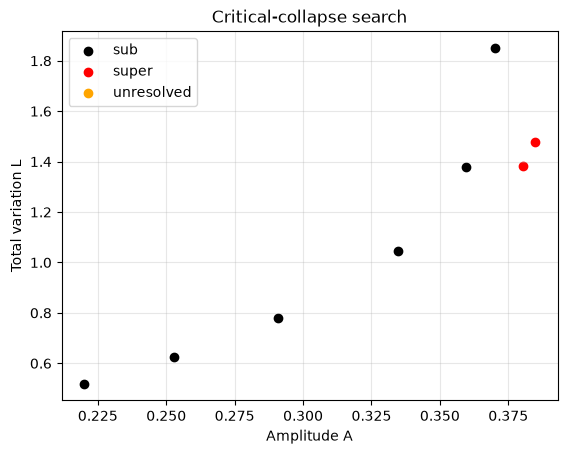

In [19]:
import numpy as np
import matplotlib.pyplot as plt

for outcome, colour in [
    ("sub", "black"),
    ("super", "red"),
    ("unresolved", "orange"),
]:
    selected = [run for run in runs if run["outcome"] == outcome]
    plt.scatter(
        [run["A"] for run in selected],
        [run["L"] for run in selected],
        color=colour,
        label=outcome,
    )

plt.xlabel("Amplitude A")
plt.ylabel("Total variation L")
plt.title("Critical-collapse search")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:


b = estimate_b(runs)

sub_runs = [
    run for run in runs
    if run["outcome"] == "sub"
    and run.get("dL_dA") is not None
    and isfinite(run["dL_dA"])
    and run["dL_dA"] > 0
]
super_runs = [run for run in runs if run["outcome"] == "super"]

anchor = max(sub_runs, key=lambda run: run["dL_dA"])
A_star_est = anchor["A"] - b / anchor["dL_dA"]

lower = max(run["A"] for run in sub_runs)
upper = min(run["A"] for run in super_runs)

print("Estimated A*:", A_star_est)
print("Current bracket:", lower, "to", upper)

Estimated A*: 0.37273576189909796
Current bracket: 0.3706740879926237 to 0.3771985001921727


Estimated b: -0.4434119021235037
Estimated A*: 0.37293546450344883
Plotted 8 points from 8 run records.


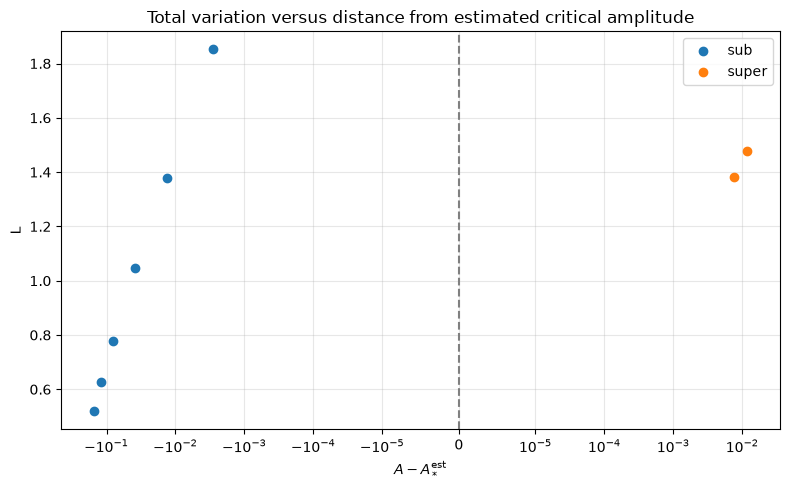

In [15]:
import numpy as np
import matplotlib.pyplot as plt

b_est = estimate_b(runs)

if b_est is None:
    raise ValueError("There isn't enough gradient data to estimate b.")

usable_sub = [
    run for run in runs
    if run["outcome"] in ("sub", "unresolved")
    and run.get("dL_dA") is not None
    and isfinite(run["dL_dA"])
    and run["dL_dA"] > 0
]

anchor = max(usable_sub, key=lambda run: abs(run["dL_dA"]))
A_star_est = anchor["A"] - b_est / anchor["dL_dA"]

print("Estimated b:", b_est)
print("Estimated A*:", A_star_est)

# Start a fresh figure so points from a previous plot cannot carry over.
fig, ax = plt.subplots(figsize=(8, 5))
points_plotted = 0

for outcome in ("sub", "super", "unresolved"):
    selected = [
        run for run in runs
        if run["outcome"] == outcome
        and np.isfinite(run["L"])
        and abs(run["A"] - A_star_est) > 0
    ]

    if selected:
        distance = np.array([
            run["A"] - A_star_est for run in selected
        ])
        L_values = np.array([run["L"] for run in selected])
        ax.scatter(distance, L_values, label=outcome)
        points_plotted += len(selected)

ax.set_xscale("symlog", linthresh=1e-5)
ax.set_xlabel(r"$A - A_*^{\mathrm{est}}$")
ax.axvline(0, color="gray", linestyle="--")
ax.set_ylabel("L")
ax.set_title("Total variation versus distance from estimated critical amplitude")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
print(f"Plotted {points_plotted} points from {len(runs)} run records.")
plt.show()


In [16]:
for run in runs:
    print(f"A={run['A']:.8f}, outcome={run['outcome']}")

A=0.22000000, outcome=sub
A=0.25300000, outcome=sub
A=0.29095000, outcome=sub
A=0.33459250, outcome=sub
A=0.38478137, outcome=super
A=0.35968694, outcome=sub
A=0.38042618, outcome=super
A=0.37005656, outcome=sub


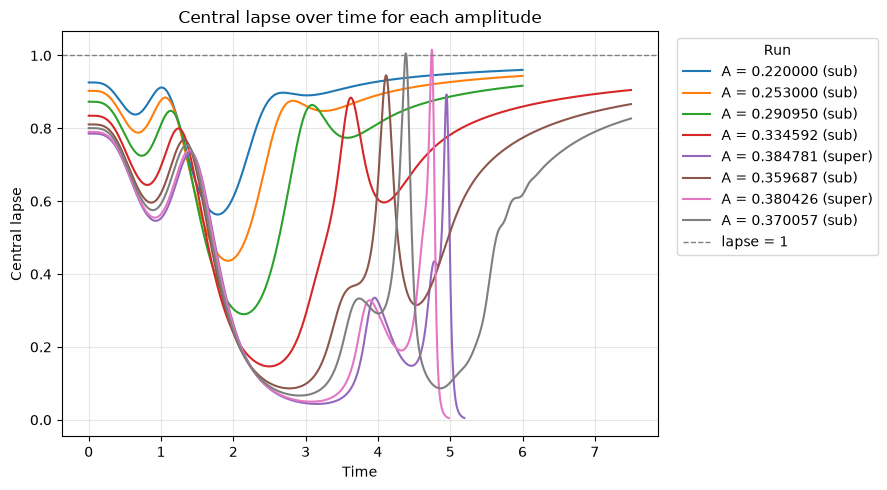

In [17]:
# Plot the central lapse history for every amplitude in runs.
import matplotlib.pyplot as plt

if not runs:
    print("There are no runs to plot yet.")
else:
    fig, ax = plt.subplots(figsize=(9, 5))

    for run in runs:
        ax.plot(
            run["lapse_times"],
            run["lapse_history"],
            label=f"A = {run['A']:.6f} ({run['outcome']})",
        )

    ax.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="lapse = 1")
    ax.set_xlabel("Time")
    ax.set_ylabel("Central lapse")
    ax.set_title("Central lapse over time for each amplitude")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Run", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    plt.show()

In [12]:
for run in sorted(runs, key=lambda run: run["A"]):
    print(
        f"A={run['A']:.8f}, L={run['L']:.5f}, "
        f"T={run['T']:.2f}, final lapse={run['final_lapse']:.5f}, "
        f"outcome={run['outcome']}"
    )

A=0.22000000, L=0.51909, T=6.00, final lapse=0.96037, outcome=sub
A=0.25300000, L=0.62589, T=6.00, final lapse=0.94404, outcome=sub
A=0.29095000, L=0.77770, T=6.00, final lapse=0.91698, outcome=sub
A=0.33459250, L=1.04600, T=7.50, final lapse=0.90522, outcome=sub
A=0.35968694, L=1.37924, T=7.50, final lapse=0.86646, outcome=sub
A=0.37005656, L=1.85188, T=7.50, final lapse=0.82701, outcome=sub
A=0.38042618, L=1.38306, T=6.00, final lapse=0.00476, outcome=super
A=0.38478137, L=1.47714, T=6.00, final lapse=0.00492, outcome=super
